In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
import cv2
import os
import PIL

In [2]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = keras.utils.get_file("flower_photos", origin=dataset_url, cache_dir="./", untar=True)

In [3]:
data_dir

'./datasets\\flower_photos'

In [4]:
import pathlib
data_dir = pathlib.Path("datasets/flower_photos/flower_photos")
data_dir

WindowsPath('datasets/flower_photos/flower_photos')

In [5]:
list(data_dir.glob("*/*.jpg"))

[WindowsPath('datasets/flower_photos/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10172636503_21bededa75_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/102841525_bd6628ae3c.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/1031799732_e7f4008c03.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10391248763_1d16681106_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437754174_22ec990b77_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437770546_8bb6f7bdd3_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/daisy/10437929963_bc13eebe0c.jpg'),
 WindowsPath('datasets/flower_photos

In [6]:
print(data_dir)
print(data_dir.exists())
print(list(data_dir.iterdir()))


datasets\flower_photos\flower_photos
True
[WindowsPath('datasets/flower_photos/flower_photos/daisy'), WindowsPath('datasets/flower_photos/flower_photos/dandelion'), WindowsPath('datasets/flower_photos/flower_photos/LICENSE.txt'), WindowsPath('datasets/flower_photos/flower_photos/roses'), WindowsPath('datasets/flower_photos/flower_photos/sunflowers'), WindowsPath('datasets/flower_photos/flower_photos/tulips')]


In [7]:
image_count = len(list(data_dir.glob("*/*.jpg")))
print(image_count)

3670


In [8]:
roses = list(data_dir.glob("roses/*.jpg"))
roses[:5]

[WindowsPath('datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

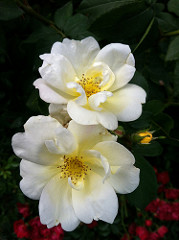

In [9]:
PIL.Image.open(str(roses[0]))

In [10]:
flowers_images_dict = {
    "roses": list(data_dir.glob("roses/*.jpg")),
    "daisy": list(data_dir.glob("daisy/*.jpg")),
    "dandelion": list(data_dir.glob("dandelion/*.jpg")),
    "sunflowers": list(data_dir.glob("sunflowers/*.jpg")),
    "tulips": list(data_dir.glob("tulips/*.jpg")),
}

In [11]:
flowers_images_dict["roses"]

[WindowsPath('datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/11102341464_508d558dfc_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/11233672494_d8bf0a3dbf_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/11694025703_9a906fedc1_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/118974357_0faa23cce9_n.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/11944957684_2cc806276e.jpg'),
 WindowsPath('datasets/flower_photos/flower_photos/roses/12045735155_42547ce4e9_n.jpg'),
 WindowsPath('datasets/flower_p

In [12]:
flowers_labels_dict = {
    "roses": 0,
    "daisy": 1,
    "dandelion": 2,
    "sunflowers": 3,
    "tulips": 4,
}

In [13]:
path_rose_1 = flowers_images_dict["roses"][0]
path_rose_1

WindowsPath('datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg')

In [14]:
img = cv2.imread(str(path_rose_1))
img.shape

(240, 179, 3)

In [15]:
cv2.resize(img, (180, 180)).shape

(180, 180, 3)

In [16]:
X, y = [], []

for flower_name, images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_image = cv2.resize(img, (180, 180))
        X.append(resized_image)
        y.append(flowers_labels_dict[flower_name])

In [17]:
X[0]

array([[[ 1, 16,  7],
        [ 1, 16,  7],
        [ 1, 17,  9],
        ...,
        [23, 50, 31],
        [25, 51, 32],
        [26, 52, 33]],

       [[10, 23, 15],
        [10, 23, 15],
        [ 9, 22, 14],
        ...,
        [20, 44, 30],
        [23, 47, 33],
        [26, 50, 36]],

       [[13, 20, 13],
        [12, 20, 13],
        [11, 19, 12],
        ...,
        [21, 43, 30],
        [22, 45, 31],
        [25, 48, 34]],

       ...,

       [[12, 24, 18],
        [11, 22, 15],
        [12, 21, 11],
        ...,
        [ 7, 14,  7],
        [ 2,  8,  2],
        [ 0,  2,  0]],

       [[19, 30, 28],
        [16, 26, 21],
        [14, 22, 15],
        ...,
        [ 3, 12,  2],
        [ 0,  8,  1],
        [ 0,  6,  1]],

       [[11, 21, 20],
        [17, 25, 24],
        [21, 28, 23],
        ...,
        [ 1, 12,  2],
        [ 2, 10,  3],
        [ 3, 10,  4]]], shape=(180, 180, 3), dtype=uint8)

In [18]:
X = np.array(X)
y = np.array(y)

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [20]:
len(X_train)

2936

In [21]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [22]:
model = keras.Sequential([
    #CNN
    keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),

    #ANN
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(5, activation="sigmoid"),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
model.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 294ms/step - accuracy: 0.4247 - loss: 1.3161
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 272ms/step - accuracy: 0.6270 - loss: 0.9487
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 253ms/step - accuracy: 0.7101 - loss: 0.7569
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 250ms/step - accuracy: 0.8134 - loss: 0.5113
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 242ms/step - accuracy: 0.8920 - loss: 0.3215
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 258ms/step - accuracy: 0.9455 - loss: 0.1630
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 275ms/step - accuracy: 0.9704 - loss: 0.0984
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 292ms/step - accuracy: 0.9799 - loss: 0.0733
Epoch 9/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 257ms/step - accuracy: 0.9833 - loss: 0.0561
Epoch 10/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 245ms/step - accuracy: 0.9932 - loss: 0.0274
Epoch 11/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 241ms/step - accuracy: 0.9874 - loss: 0.0511
Epoch 12/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 22

In [23]:
model.evaluate(X_test_scaled, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.6553 - loss: 2.6122


[2.6121575832366943, 0.6553133726119995]

In [24]:
yp = model.predict(X_test_scaled)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step


In [25]:
yp[0]

array([3.1047760e-02, 1.0000000e+00, 3.4309560e-01, 4.8458322e-08,
       1.7923499e-04], dtype=float32)

In [26]:
y_pred = [np.argmax(y) for y in yp]
y_pred[:10]

[np.int64(1),
 np.int64(0),
 np.int64(2),
 np.int64(4),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(1),
 np.int64(3),
 np.int64(0)]

In [27]:
y_test[:10]

array([1, 0, 2, 4, 2, 3, 0, 4, 3, 4])

In [28]:
# Data Augmentation
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal", input_shape=(180, 180, 3)),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1)
])

D:\Data Science\.venv\lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [29]:
model = keras.Sequential([
    data_augmentation,
    #CNN
    keras.layers.Conv2D(16, 3, activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    keras.layers.MaxPooling2D(),

    #ANN
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(5, activation="sigmoid"),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 35s 343ms/step - accuracy: 0.3896 - loss: 1.4439
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 324ms/step - accuracy: 0.5715 - loss: 1.0711
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 327ms/step - accuracy: 0.6301 - loss: 0.9561
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 337ms/step - accuracy: 0.6580 - loss: 0.8940
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 313ms/step - accuracy: 0.6785 - loss: 0.8332
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 349ms/step - accuracy: 0.6945 - loss: 0.7825
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 33s 355ms/step - accuracy: 0.7146 - loss: 0.7531
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 318ms/step - accuracy: 0.7333 - loss: 0.7152
Epoch 9/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 337ms/step - accuracy: 0.7340 - loss: 0.6838
Epoch 10/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 351ms/step - accuracy: 0.7486 - loss: 0.6499
Epoch 11/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 333ms/step - accuracy: 0.7691 - loss: 0.6134
Epoch 12/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 32

In [30]:
model.evaluate(X_test_scaled, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.7534 - loss: 0.8780


[0.8779953122138977, 0.7534059882164001]